---
# Phase 1 — Data loading, profiling and pre-processing


- $\mu$: each stock's expected annual return
- $\Sigma$: the covariance matrix, i.e. how stock returns move together, which drives portfolio risk

and keep an unseen final year for validation.

In [1]:
from math import comb
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW_PATH      = Path("../data/raw/all_stocks_5yr.csv")
PROCESSED_DIR = Path("../data/processed")
MIN_COVERAGE  = 0.98    # keep tickers present on at least 98% of trading days
CRASH_LIMIT   = -0.35   # a one-day drop below −35% is treated as an unadjusted corporate action
TEST_DAYS     = 252     # final trading year held out for out-of-sample validation
TRADING_DAYS  = 252     # annualisation factor

C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "gray": "#8a8984", "ink2": "#52514e"}
plt.rcParams.update({
    "figure.figsize": (9, 4), "figure.dpi": 110, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": "#c9c8c2", "axes.grid": True,
    "grid.color": "#ecebe6", "grid.linewidth": 0.8, "lines.linewidth": 2,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelcolor": C["ink2"],
    "xtick.color": C["ink2"], "ytick.color": C["ink2"], "legend.frameon": False,
})

## 1.1 Load the raw data

In [2]:
raw = pd.read_csv(RAW_PATH, parse_dates=["date"])
print(f"Rows: {len(raw):,}  |  tickers: {raw['Name'].nunique()}  |  "
      f"{raw['date'].min().date()} → {raw['date'].max().date()} ({raw['date'].nunique()} trading days)")
raw.head()

Rows: 619,040  |  tickers: 505  |  2013-02-08 → 2018-02-07 (1259 trading days)


,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL


## 1.2 Profile the data

1. Missing values and data types
2. Duplicate rows and impossible prices
3. Whether every stock covers the full period
4. Suspicious one-day price moves

In [3]:
print(pd.DataFrame({"missing values": raw.isna().sum(), "dtype": raw.dtypes.astype(str)}), "\n")
print("Duplicate (date, ticker) rows:", raw.duplicated(["date", "Name"]).sum())
print("Prices ≤ 0:", int((raw[["open", "high", "low", "close"]] <= 0).sum().sum()))

        missing values           dtype
date                 0  datetime64[ns]
open                11         float64
high                 8         float64
low                  8         float64
close                0         float64
volume               0           int64
Name                 0          object 

Duplicate (date, ticker) rows: 0
Prices ≤ 0: 0


Tickers with the full 1259-day history: 470 of 505
Shortest histories: {'APTV': 44, 'DWDP': 109, 'BHF': 143, 'BHGE': 152, 'DXC': 215, 'HLT': 276, 'EVHC': 297, 'FTV': 404}


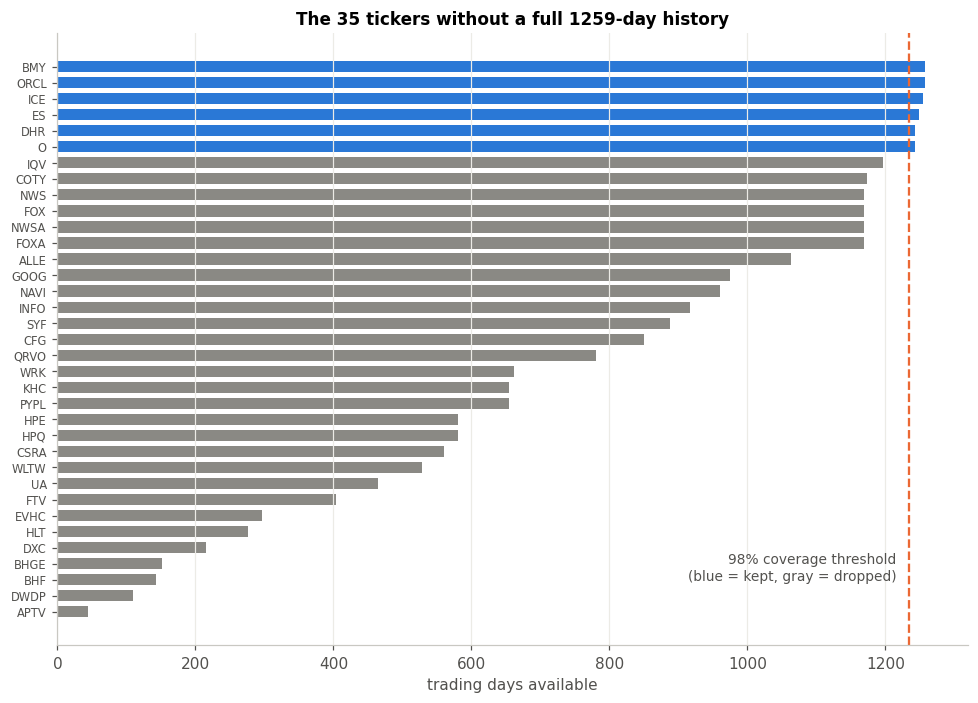

In [4]:
history = raw.groupby("Name").size()
full = history.max()
print(f"Tickers with the full {full}-day history: {(history == full).sum()} of {len(history)}")
print("Shortest histories:", history.nsmallest(8).to_dict())

short = history[history < full].sort_values()
fig, ax = plt.subplots(figsize=(9, 6.5))
keep = short >= MIN_COVERAGE * full
ax.barh(short.index, short.values, color=np.where(keep, C["blue"], C["gray"]), height=0.7)
ax.axvline(MIN_COVERAGE * full, color=C["orange"], ls="--", lw=1.5)
ax.annotate(f"{MIN_COVERAGE:.0%} coverage threshold\n(blue = kept, gray = dropped)", (MIN_COVERAGE * full, 2),
            xytext=(-8, 0), textcoords="offset points", ha="right", fontsize=9, color=C["ink2"])
ax.tick_params(axis="y", labelsize=7.5)
ax.grid(axis="y", visible=False)
ax.set(title=f"The {len(short)} tickers without a full {full}-day history", xlabel="trading days available")
plt.tight_layout(); plt.show()

In [5]:
close_raw = raw.pivot(index="date", columns="Name", values="close")
moves = close_raw.pct_change(fill_method=None).stack()
extreme = moves[moves.abs() > 0.35].sort_values().rename("one-day return").to_frame()
extreme.style.format("{:+.1%}")

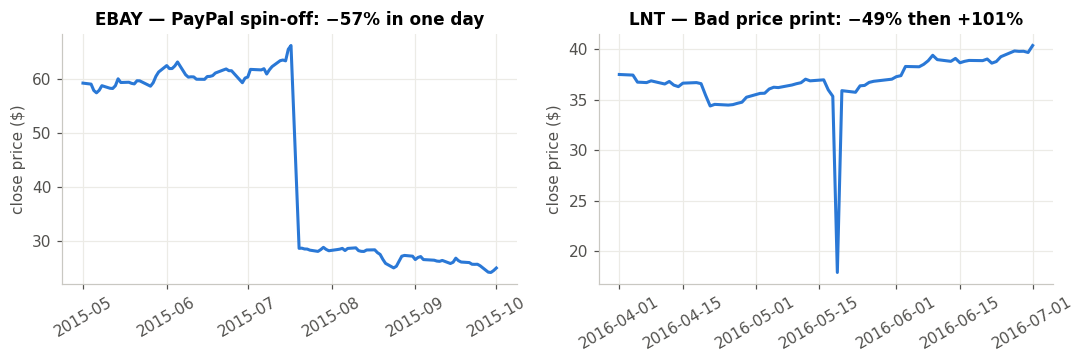

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, (tkr, start, end, note) in zip(axes, [
        ("EBAY", "2015-05-01", "2015-10-01", "PayPal spin-off: −57% in one day"),
        ("LNT",  "2016-04-01", "2016-07-01", "Bad price print: −49% then +101%")]):
    s = close_raw.loc[start:end, tkr]
    ax.plot(s.index, s.values, color=C["blue"])
    ax.set(title=f"{tkr} — {note}", ylabel="close price ($)")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

In [7]:
# 1.3.1  Closing-price table: rows = trading days, columns = tickers
prices = raw.pivot(index="date", columns="Name", values="close").sort_index()
n_start = prices.shape[1]

# 1.3.2  Coverage filter, then forward-fill remaining short gaps
coverage = prices.notna().mean()
low_cov  = coverage[coverage < MIN_COVERAGE].index
gappy    = coverage[(coverage >= MIN_COVERAGE) & (coverage < 1)].index
prices   = prices.drop(columns=low_cov).ffill()

# 1.3.3  Remove tickers with unadjusted corporate actions
daily_simple = prices.pct_change()
artefacts    = daily_simple.columns[(daily_simple < CRASH_LIMIT).any()]
prices       = prices.drop(columns=artefacts)

# 1.3.4  Daily log returns
log_ret = np.log(prices / prices.shift(1)).iloc[1:]
assert not log_ret.isna().any().any(), "returns table must be complete"

pd.DataFrame({
    "tickers": [n_start, n_start - len(low_cov), prices.shape[1], log_ret.shape[1]],
    "detail": [
        "raw",
        f"dropped {len(low_cov)} with < {MIN_COVERAGE:.0%} coverage; forward-filled {len(gappy)}: {', '.join(gappy)}",
        f"dropped {len(artefacts)} corporate-action artefacts: {', '.join(artefacts)}",
        f"{log_ret.shape[0]} days of log returns, 0 missing values",
    ]}, index=["1.3.1 pivot", "1.3.2 coverage", "1.3.3 artefacts", "1.3.4 log returns"])

,tickers,detail
1.3.1 pivot,505,raw
1.3.2 coverage,476,dropped 29 with < 98% coverage; forward-filled...
1.3.3 artefacts,470,"dropped 6 corporate-action artefacts: BAX, DIS..."
1.3.4 log returns,470,"1258 days of log returns, 0 missing values"


In [8]:
# 1.3.5  Time-ordered split
train_ret = log_ret.iloc[:-TEST_DAYS]
test_ret  = log_ret.iloc[-TEST_DAYS:]
print(f"In-sample (estimate μ, Σ):  {train_ret.index[0].date()} → {train_ret.index[-1].date()}  ({len(train_ret)} days)")
print(f"Out-of-sample (validate):  {test_ret.index[0].date()} → {test_ret.index[-1].date()}  ({len(test_ret)} days)")

# 1.3.6  Annualised model parameters
tickers = train_ret.columns.to_numpy()
mu      = train_ret.mean().to_numpy() * TRADING_DAYS     # expected annual return of each stock
Sigma   = train_ret.cov().to_numpy()  * TRADING_DAYS     # annual covariance matrix
N       = len(mu)
vol     = np.sqrt(np.diag(Sigma))                        # each stock's own annual volatility

In-sample (estimate μ, Σ):  2013-02-11 → 2017-02-07  (1006 days)
Out-of-sample (validate):  2017-02-08 → 2018-02-07  (252 days)


## 1.4 Sanity checks on the model inputs

- $\Sigma$ is a valid covariance matrix: symmetric and positive semi-definite, so every portfolio variance $x^\top\Sigma x \ge 0$
- The values are financially plausible
- The problem is too large for exhaustive search at each *k* we plan to use

In [9]:
eig_min = np.linalg.eigvalsh(Sigma).min()
print(f"N = {N} stocks")
print(f"Σ symmetric: {np.allclose(Sigma, Sigma.T)}  |  smallest eigenvalue: {eig_min:.2e}  →  PSD: {eig_min > -1e-10}")

pd.DataFrame({
    "annual return μ":    pd.Series(mu).describe(percentiles=[.1, .5, .9]),
    "annual volatility σ": pd.Series(vol).describe(percentiles=[.1, .5, .9]),
}).loc[["min", "10%", "50%", "90%", "max"]].style.format("{:.1%}")

N = 470 stocks
Σ symmetric: True  |  smallest eigenvalue: 1.11e-03  →  PSD: True


,annual return μ,annual volatility σ
min,-29.7%,14.0%
10%,-1.7%,17.1%
50%,10.9%,23.2%
90%,23.2%,33.5%
max,56.7%,69.4%


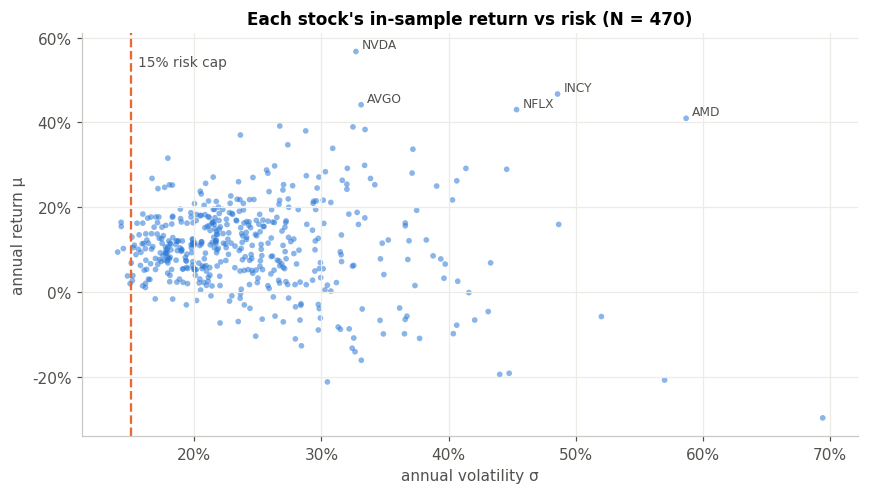

Stocks that individually satisfy the 15% cap: 6 of 470


In [10]:
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.scatter(vol, mu, s=14, color=C["blue"], alpha=0.55, edgecolor="none")
ax.axvline(0.15, color=C["orange"], ls="--", lw=1.5)
ax.annotate("15% risk cap", (0.15, mu.max()), xytext=(5, -2), textcoords="offset points",
            fontsize=9, color=C["ink2"], va="top")
for i in np.argsort(mu)[-5:]:
    ax.annotate(tickers[i], (vol[i], mu[i]), xytext=(4, 2), textcoords="offset points", fontsize=8, color=C["ink2"])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(title=f"Each stock's in-sample return vs risk (N = {N})", xlabel="annual volatility σ", ylabel="annual return μ")
plt.tight_layout(); plt.show()
print(f"Stocks that individually satisfy the 15% cap: {(vol <= 0.15).sum()} of {N}")

In [11]:
print("Search space size C(N, k) for the planned k values:")
for k in (5, 10, 20):
    print(f"  k = {k:>2}:  {comb(N, k):.2e} possible portfolios")

Search space size C(N, k) for the planned k values:
  k =  5:  1.87e+11 possible portfolios
  k = 10:  1.32e+20 possible portfolios
  k = 20:  7.55e+34 possible portfolios


In [12]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
log_ret.to_csv(PROCESSED_DIR / "log_returns_clean.csv")
print("Saved", PROCESSED_DIR / "log_returns_clean.csv", log_ret.shape)

Saved ../data/processed/log_returns_clean.csv (1258, 470)


In [13]:
# ---- Problem configuration (Phase 2) ---------------------------------------
K         = 5       # stocks to select (later: 10 and 20)
LAMBDA    = 2.0     # risk aversion λ
RISK_CAP  = 0.15    # σ_max: maximum annual portfolio volatility

# A solution S is an array of k distinct stock indices, equivalent to x with exactly k ones.

def port_return(S):
    # R(x) = (1/k) μᵀx
    return mu[S].mean()

def port_vol(S):
    # σp(x) = (1/k) √(xᵀΣx), using only the k×k block of Σ for the selected stocks
    S = np.asarray(S)
    return np.sqrt(Sigma[np.ix_(S, S)].sum()) / len(S)

def objective(S, lam=LAMBDA):
    # f(x) = R(x) − λ σp(x)²  (to maximise)
    return port_return(S) - lam * port_vol(S) ** 2

def violation(S, cap=RISK_CAP):
    # amount by which the risk cap is exceeded (0 if feasible)
    return max(0.0, port_vol(S) - cap)

def is_feasible(S, k=K, cap=RISK_CAP):
    S = np.asarray(S)
    return len(S) == k and len(np.unique(S)) == k and port_vol(S) <= cap

def energy(S, rho, lam=LAMBDA, cap=RISK_CAP):
    # E(x; ρ) = −f(x) + ρ · max(0, σp − σmax)²  (to minimise)
    return -objective(S, lam) + rho * violation(S, cap) ** 2

## 2.1 Verify the formulation code

In [14]:
rng = np.random.default_rng(42)
tests = [rng.choice(N, size=K, replace=False) for _ in range(200)]

# 1. Index-set version == full binary-vector formulation
for S in tests:
    x = np.zeros(N); x[S] = 1
    assert np.isclose(port_return(S), mu @ x / K)
    assert np.isclose(port_vol(S) ** 2, x @ Sigma @ x / K**2)
    assert np.isclose(objective(S), mu @ x / K - LAMBDA * x @ Sigma @ x / K**2)
print("✓ 1. R, σp and f match the binary-vector formulas (200 random portfolios)")

# 2. σp matches the realised volatility of the equal-weight portfolio's daily returns
for S in tests[:50]:
    realised = train_ret.iloc[:, S].mean(axis=1).std() * np.sqrt(TRADING_DAYS)
    assert np.isclose(port_vol(S), realised)
print("✓ 2. σp matches the realised volatility of the portfolio's daily returns")

✓ 1. R, σp and f match the binary-vector formulas (200 random portfolios)
✓ 2. σp matches the realised volatility of the portfolio's daily returns


In [15]:
S_feas  = np.argsort(vol)[:K]               # the k least volatile stocks
S_infea = np.argsort(mu)[::-1][:K]          # the k highest-return stocks (ignores risk)

pd.DataFrame({
    "portfolio": ["k least volatile", "k highest return"],
    "stocks": [", ".join(tickers[S_feas]), ", ".join(tickers[S_infea])],
    "return R": [port_return(S_feas), port_return(S_infea)],
    "volatility σp": [port_vol(S_feas), port_vol(S_infea)],
    "f(x)": [objective(S_feas), objective(S_infea)],
    "feasible": [is_feasible(S_feas), is_feasible(S_infea)],
}).style.format({"return R": "{:+.1%}", "volatility σp": "{:.1%}", "f(x)": "{:.4f}"}).hide(axis="index")

portfolio,stocks,return R,volatility σp,f(x),feasible
k least volatile,"PEP, WM, RSG, JNJ, PG",+11.0%,11.0%,0.0862,True
k highest return,"NVDA, INCY, AVGO, NFLX, AMD",+46.3%,27.5%,0.3123,False


In [16]:
import time

# ---- SA configuration (Phase 3) -------------------------------------------
ALPHA      = 0.95     # cooling rate: T ← αT
MOVES_PER_T = 500      # neighbours tried at each temperature level
T_MIN_RATIO = 1e-4     # stop when T < T0 · 1e-4
P0          = 0.5      # acceptance probability of a typical worse move at T0
FROZEN_LEVELS = 10     # stop early after this many feasible levels with no accepted move
N_SEEDS     = 30       # independent runs for verification
UNIVERSE    = np.arange(N)   # candidate stocks (all N; a subset for the brute-force check)

In [17]:
def calibrate(k, universe=UNIVERSE, p0=P0, samples=3000, seed=123):
    rng = np.random.default_rng(seed)
    worse, viol = [], []
    for _ in range(samples):
        S = rng.choice(universe, size=k, replace=False)
        outside = np.setdiff1d(universe, S)
        S_new = S.copy(); S_new[rng.integers(k)] = rng.choice(outside)
        dE = objective(S) - objective(S_new)           # ΔE of −f, without penalty
        if dE > 0:
            worse.append(dE)
        if violation(S) > 0:
            viol.append(violation(S))
    dE_typ, v_typ = np.mean(worse), np.median(viol)
    return -dE_typ / np.log(p0), dE_typ / v_typ**2, dE_typ, v_typ

T0, RHO0, dE_typ, v_typ = calibrate(K)
levels = int(np.ceil(np.log(T_MIN_RATIO) / np.log(ALPHA)))
rho_end = RHO0 / T_MIN_RATIO**2

print(f"typical worse move ΔE⁺ = {dE_typ:.4f}   |   typical violation = {v_typ:.2%} over the cap")
print(f"T0 = {T0:.4f}  →  T_min = {T0 * T_MIN_RATIO:.2e}")
print(f"ρ0 = {RHO0:,.1f}  →  ρ_end = {rho_end:,.0f}")
print(f"at most {levels} temperature levels × {MOVES_PER_T} moves = {levels * MOVES_PER_T:,} moves per run")
print(f"Cost of being 0.1% over the cap: start {RHO0 * 0.001**2:.5f}, end {rho_end * 0.001**2:.3f} "
      f"(vs typical ΔE⁺ {dE_typ:.4f})")
print(f"Cost of being 0.01% over the cap at the end: {rho_end * 0.0001**2:.2f}")

typical worse move ΔE⁺ = 0.0246   |   typical violation = 1.96% over the cap
T0 = 0.0355  →  T_min = 3.55e-06
ρ0 = 64.1  →  ρ_end = 6,408,436,352
at most 180 temperature levels × 500 moves = 90,000 moves per run
Cost of being 0.1% over the cap: start 0.00006, end 6408.436 (vs typical ΔE⁺ 0.0246)
Cost of being 0.01% over the cap at the end: 64.08


In [18]:
def simulated_annealing(k, T0, rho0, universe=UNIVERSE, alpha=ALPHA, moves=MOVES_PER_T,
                        t_min_ratio=T_MIN_RATIO, frozen_levels=FROZEN_LEVELS, seed=0):
    rng = np.random.default_rng(seed)
    S = rng.choice(universe, size=k, replace=False)          # random start (often over the cap)
    outside = np.setdiff1d(universe, S)
    T, rho = T0, rho0
    E = energy(S, rho)
    best_S, best_f = None, -np.inf                           # best FEASIBLE portfolio seen
    history, idle = [], 0

    while T > t_min_ratio * T0 and idle < frozen_levels:
        accepted = 0
        for _ in range(moves):
            i, j = rng.integers(k), rng.integers(len(outside))
            S_new = S.copy(); S_new[i] = outside[j]          # swap move
            dE = energy(S_new, rho) - E
            if dE <= 0 or rng.random() < np.exp(-dE / T):    # Metropolis acceptance
                outside[j] = S[i]
                S, E = S_new, E + dE
                accepted += 1
                if violation(S) == 0 and objective(S) > best_f:
                    best_S, best_f = S.copy(), objective(S)
        history.append({"T": T, "rho": rho, "f": objective(S), "vol": port_vol(S),
                        "best_f": best_f, "accept_rate": accepted / moves})
        # frozen = no accepted move while feasible (an infeasible state is still pushed out by the growing ρ)
        idle = idle + 1 if accepted == 0 and violation(S) == 0 else 0
        T, rho = alpha * T, rho / alpha**2                   # cool down, tighten the penalty
        E = energy(S, rho)                                   # re-score under the new ρ
    return best_S, best_f, pd.DataFrame(history)


def improving_swap(S, universe=UNIVERSE):
    # Return a feasible 1-swap neighbour with higher f, or None if S is a local optimum
    f_S = objective(S)
    for i in range(len(S)):
        for b in np.setdiff1d(universe, S):
            S2 = S.copy(); S2[i] = b
            if is_feasible(S2) and objective(S2) > f_S + 1e-12:
                return S2
    return None

def polish(S, universe=UNIVERSE):
    # Post-processing: apply improving feasible swaps until none remain (Lec 10 s14)
    while (S2 := improving_swap(S, universe)) is not None:
        S = S2
    return S

## 3.3 Single run (seed 0)

In [19]:
t0 = time.perf_counter()
S_raw, f_raw, hist = simulated_annealing(K, T0, RHO0, seed=0)
S_sa = polish(S_raw); f_sa = objective(S_sa)
t_run = time.perf_counter() - t0

print(f"Run time {t_run:.2f}s  |  {len(hist) * MOVES_PER_T:,} moves ({len(hist)} levels)  |  "
      f"SA f = {f_raw:.4f}, after polish f = {f_sa:.4f}")
pd.DataFrame({
    "ticker": tickers[S_sa], "annual μ": mu[S_sa], "annual σ": vol[S_sa],
}).sort_values("annual μ", ascending=False).style.format({"annual μ": "{:+.1%}", "annual σ": "{:.1%}"}).hide(axis="index")

Run time 0.83s  |  58,500 moves (117 levels)  |  SA f = 0.3123, after polish f = 0.3123


ticker,annual μ,annual σ
NVDA,+56.7%,32.7%
STZ,+39.1%,26.7%
HII,+37.0%,23.6%
LMT,+26.8%,16.7%
MO,+18.4%,16.0%


Portfolio: return +35.6%, volatility 14.80%, f = 0.3123, feasible = True


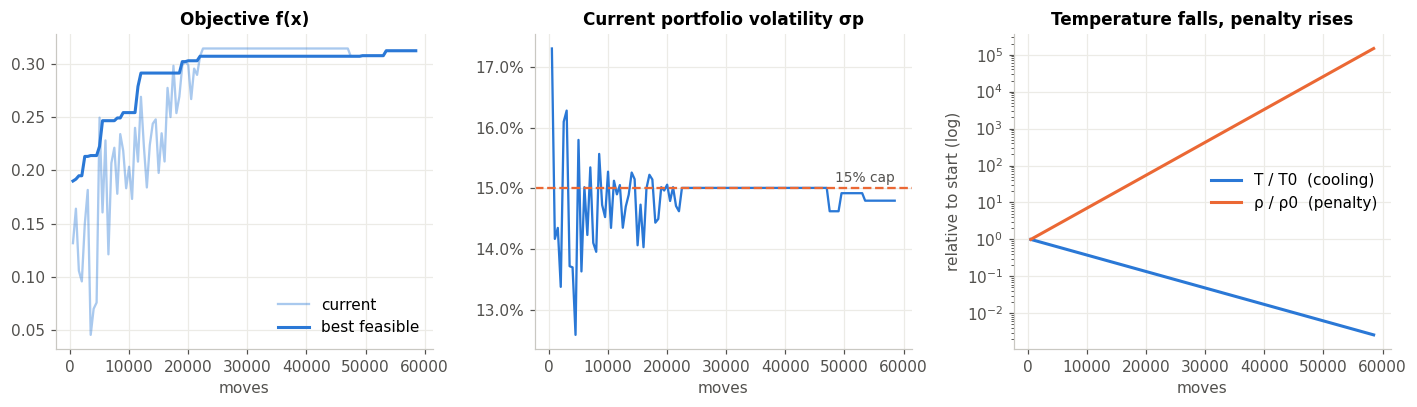

In [20]:
print(f"Portfolio: return {port_return(S_sa):+.1%}, volatility {port_vol(S_sa):.2%}, f = {f_sa:.4f}, "
      f"feasible = {is_feasible(S_sa)}")

moves_axis = np.arange(1, len(hist) + 1) * MOVES_PER_T
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

axes[0].plot(moves_axis, hist["f"], color=C["blue"], alpha=0.4, lw=1.5, label="current")
axes[0].plot(moves_axis, hist["best_f"], color=C["blue"], label="best feasible")
axes[0].set(title="Objective f(x)", xlabel="moves")
axes[0].legend(loc="lower right")

axes[1].plot(moves_axis, hist["vol"], color=C["blue"], lw=1.5)
axes[1].axhline(RISK_CAP, color=C["orange"], ls="--", lw=1.5)
axes[1].annotate("15% cap", (moves_axis[-1], RISK_CAP), xytext=(0, 4), textcoords="offset points",
                 ha="right", fontsize=9, color=C["ink2"])
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
axes[1].set(title="Current portfolio volatility σp", xlabel="moves")

axes[2].semilogy(moves_axis, hist["T"] / T0, color=C["blue"], label="T / T0  (cooling)")
axes[2].semilogy(moves_axis, hist["rho"] / RHO0, color=C["orange"], label="ρ / ρ0  (penalty)")
axes[2].set(title="Temperature falls, penalty rises", xlabel="moves", ylabel="relative to start (log)")
axes[2].legend(loc="center right")
plt.tight_layout(); plt.show()

## 3.4 Verification of the SA solutions

1. FEASIBILITY & LOCAL OPTIMALITY
   polish changed the SA result in:          2/30 runs
   exactly k distinct stocks and σp ≤ 15%:   30/30 runs
   no improving feasible 1-swap neighbour:   30/30 runs (checked 2,325 neighbours each)

2. CONVERGENCE & 30-SEED STATISTICS


mean f,std f,best f,worst f,runs reaching best,SA alone reaching best,distinct solutions,mean moves,mean time (s)
0.31187,0.00163,0.31230,0.30529,28/30,27/30,3,"46,117",0.68


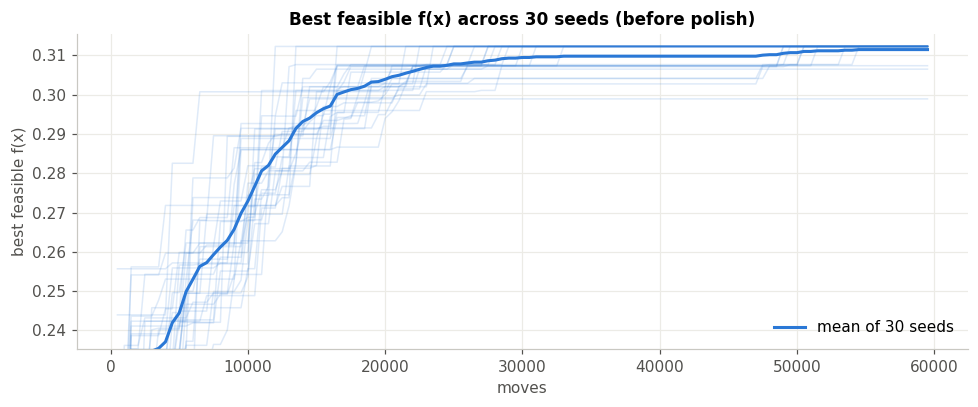

3. BRUTE-FORCE REFERENCE (40 random stocks, k = 5)
   enumerated 658,008 portfolios (153,255 feasible) in 0.31s
   optimum f* = 0.14313: AWK, CME, IT, KR, MA (σp = 13.51%)
   SA reached f* in 30/30 runs; optimality gap mean 0.000%, max 0.000%; 0.72s per run


In [21]:
from IPython.display import display
from itertools import combinations

# =============================================================================
# 1. Feasibility & local optimality — every one of the 30 runs (Lec 1 s144, Lec 2 s325)
# =============================================================================
runs = []
for seed in range(N_SEEDS):
    t0 = time.perf_counter()
    S_raw, f_raw, h_s = simulated_annealing(K, T0, RHO0, seed=seed)
    S_s = polish(S_raw)
    runs.append({"seed": seed, "S": S_s, "f": objective(S_s), "f_raw": f_raw,
                 "time_s": time.perf_counter() - t0, "moves": len(h_s) * MOVES_PER_T,
                 "curve": h_s["best_f"].to_numpy(), "solution": tuple(sorted(tickers[S_s]))})
runs = pd.DataFrame(runs)

feasible  = [S is not None and is_feasible(S) for S in runs["S"]]
local_opt = [improving_swap(S) is None for S in runs["S"]]
print("1. FEASIBILITY & LOCAL OPTIMALITY")
print(f"   polish changed the SA result in:          {(~np.isclose(runs['f'], runs['f_raw'])).sum()}/{N_SEEDS} runs")
print(f"   exactly k distinct stocks and σp ≤ 15%:   {sum(feasible)}/{N_SEEDS} runs")
print(f"   no improving feasible 1-swap neighbour:   {sum(local_opt)}/{N_SEEDS} runs "
      f"(checked {K * (N - K):,} neighbours each)")

# =============================================================================
# 2. Convergence & 30-seed statistics (Lec 10 s27, Lec 1 s62, master guide §3.2)
# =============================================================================
best_overall = runs["f"].max()
print("\n2. CONVERGENCE & 30-SEED STATISTICS")
display(pd.DataFrame({
    "mean f": [runs["f"].mean()], "std f": [runs["f"].std()],
    "best f": [best_overall], "worst f": [runs["f"].min()],
    "runs reaching best": [f"{np.isclose(runs['f'], best_overall).sum()}/{N_SEEDS}"],
    "SA alone reaching best": [f"{np.isclose(runs['f_raw'], best_overall).sum()}/{N_SEEDS}"],
    "distinct solutions": [runs["solution"].nunique()],
    "mean moves": [runs["moves"].mean()],
    "mean time (s)": [runs["time_s"].mean()],
}).style.format({"mean f": "{:.5f}", "std f": "{:.5f}", "best f": "{:.5f}", "worst f": "{:.5f}",
                 "mean moves": "{:,.0f}", "mean time (s)": "{:.2f}"}).hide(axis="index"))

L_max = max(len(c) for c in runs["curve"])                 # runs stop at different levels
curves = np.vstack([np.pad(c, (0, L_max - len(c)), mode="edge") for c in runs["curve"]])
curves[~np.isfinite(curves)] = np.nan
moves_axis = np.arange(1, L_max + 1) * MOVES_PER_T
fig, ax = plt.subplots(figsize=(9, 3.8))
for c in curves:
    ax.plot(moves_axis, c, color=C["blue"], alpha=0.15, lw=1)
ax.plot(moves_axis, np.nanmean(curves, axis=0), color=C["blue"], label=f"mean of {N_SEEDS} seeds")
ax.set(title="Best feasible f(x) across 30 seeds (before polish)", xlabel="moves", ylabel="best feasible f(x)")
ax.set_ylim(np.nanpercentile(curves, 5), best_overall + 0.01 * abs(best_overall))
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

# =============================================================================
# 3. Brute-force reference on a small instance (Lec 5 s68, Lec 11 s60)
# =============================================================================
SUB = np.sort(np.random.default_rng(7).choice(N, size=40, replace=False))
t0 = time.perf_counter()
combos = SUB[np.array(list(combinations(range(len(SUB)), K)))]
blocks = Sigma[combos[:, :, None], combos[:, None, :]].sum(axis=(1, 2))
vols   = np.sqrt(blocks) / K
fs     = mu[combos].mean(axis=1) - LAMBDA * vols**2
fs[vols > RISK_CAP] = -np.inf                       # infeasible portfolios excluded
f_star, S_star = fs.max(), combos[fs.argmax()]
t_bf = time.perf_counter() - t0

T0_s, RHO0_s, _, _ = calibrate(K, universe=SUB)
sub_f, sub_t = [], []
for seed in range(N_SEEDS):
    t0 = time.perf_counter()
    S_raw, _, _ = simulated_annealing(K, T0_s, RHO0_s, universe=SUB, seed=seed)
    sub_f.append(objective(polish(S_raw, SUB))); sub_t.append(time.perf_counter() - t0)
gap = (f_star - np.array(sub_f)) / abs(f_star) * 100

print("3. BRUTE-FORCE REFERENCE (40 random stocks, k = 5)")
print(f"   enumerated {len(combos):,} portfolios ({np.isfinite(fs).sum():,} feasible) in {t_bf:.2f}s")
print(f"   optimum f* = {f_star:.5f}: {', '.join(sorted(tickers[S_star]))} (σp = {port_vol(S_star):.2%})")
print(f"   SA reached f* in {(gap < 1e-9).sum()}/{N_SEEDS} runs; optimality gap mean {gap.mean():.3f}%, "
      f"max {gap.max():.3f}%; {np.mean(sub_t):.2f}s per run")